In [2]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

In [3]:
PROJECT_ROOT = Path(r"C:\Case Study Trees\HomeCreditStudy")

SPLIT_DIR = PROJECT_ROOT / "data" / "splits"

df = pd.read_csv(SPLIT_DIR / "train.csv")

print("Training rows:", df.shape[0])
print("Columns:", df.shape[1])

df.head()

Training rows: 215257
Columns: 122


,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,289726,0,Cash loans,M,Y,Y,3,225000.0,450000.0,30442.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
1,262888,0,Revolving loans,F,N,N,0,225000.0,337500.0,16875.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,3.0
2,206259,1,Revolving loans,F,N,Y,0,76500.0,180000.0,9000.0,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
3,237779,0,Cash loans,F,N,Y,0,157500.0,1546020.0,45333.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
4,215975,0,Cash loans,M,N,N,0,103500.0,254700.0,26743.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0


In [6]:
df.info(verbose=True, show_counts=True)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 215257 entries, 0 to 215256
Data columns (total 122 columns):
 #    Column                        Non-Null Count   Dtype  
---   ------                        --------------   -----  
 0    SK_ID_CURR                    215257 non-null  int64  
 1    TARGET                        215257 non-null  int64  
 2    NAME_CONTRACT_TYPE            215257 non-null  object 
 3    CODE_GENDER                   215257 non-null  object 
 4    FLAG_OWN_CAR                  215257 non-null  object 
 5    FLAG_OWN_REALTY               215257 non-null  object 
 6    CNT_CHILDREN                  215257 non-null  int64  
 7    AMT_INCOME_TOTAL              215257 non-null  float64
 8    AMT_CREDIT                    215257 non-null  float64
 9    AMT_ANNUITY                   215248 non-null  float64
 10   AMT_GOODS_PRICE               215065 non-null  float64
 11   NAME_TYPE_SUITE               214364 non-null  object 
 12   NAME_INCOME_TYPE            

In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
SK_ID_CURR,215257.0,278298.047172,102841.209266,100002.0,189068.0,278424.0,367427.0,456255.0
TARGET,215257.0,0.080727,0.272416,0.0,0.0,0.0,0.0,1.0
CNT_CHILDREN,215257.0,0.415108,0.719736,0.0,0.0,0.0,1.0,19.0
AMT_INCOME_TOTAL,215257.0,169073.867494,274425.748371,25650.0,112500.0,148500.0,202500.0,117000000.0
AMT_CREDIT,215257.0,599618.714462,403093.915532,45000.0,270000.0,514777.5,808650.0,4050000.0
...,...,...,...,...,...,...,...,...
AMT_REQ_CREDIT_BUREAU_DAY,186077.0,0.006863,0.109675,0.0,0.0,0.0,0.0,9.0
AMT_REQ_CREDIT_BUREAU_WEEK,186077.0,0.034733,0.207043,0.0,0.0,0.0,0.0,8.0
AMT_REQ_CREDIT_BUREAU_MON,186077.0,0.268319,0.922429,0.0,0.0,0.0,0.0,27.0
AMT_REQ_CREDIT_BUREAU_QRT,186077.0,0.264627,0.613276,0.0,0.0,0.0,0.0,19.0


In [13]:
missing_summary = pd.DataFrame({
    "Missing_Count": df.isna().sum(),
    "Missing_Percentage": (df.isna().mean() * 100).round(2)
})

missing_summary = missing_summary[
    missing_summary["Missing_Percentage"] > 50
].sort_values("Missing_Count", ascending=False)

display(missing_summary)

,Missing_Count,Missing_Percentage
COMMONAREA_AVG,150428,69.88
COMMONAREA_MEDI,150428,69.88
COMMONAREA_MODE,150428,69.88
NONLIVINGAPARTMENTS_AVG,149464,69.44
NONLIVINGAPARTMENTS_MODE,149464,69.44
NONLIVINGAPARTMENTS_MEDI,149464,69.44
FONDKAPREMONT_MODE,147244,68.40
LIVINGAPARTMENTS_AVG,147194,68.38
LIVINGAPARTMENTS_MODE,147194,68.38
LIVINGAPARTMENTS_MEDI,147194,68.38


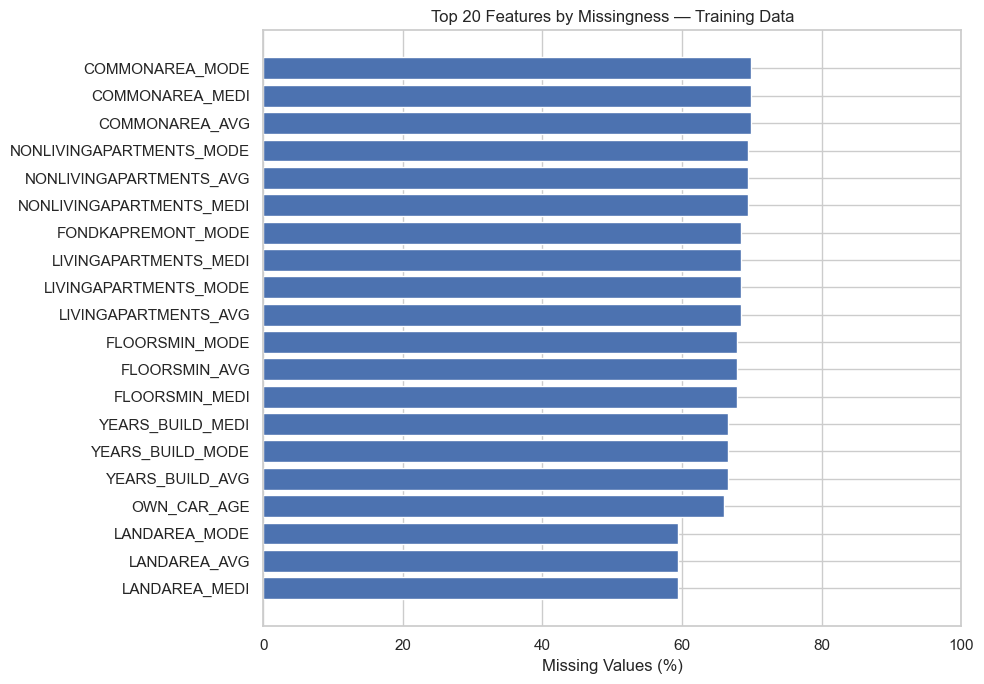

In [14]:
top_missing = missing_summary.head(20).sort_values("Missing_Percentage")

plt.figure(figsize=(10, 7))

plt.barh(
    top_missing.index,
    top_missing["Missing_Percentage"]
)

plt.title("Top 20 Features by Missingness — Training Data")
plt.xlabel("Missing Values (%)")
plt.xlim(0, 100)
plt.tight_layout()
plt.show()

,Count,Percentage
TARGET,,
0,197880,91.93
1,17377,8.07


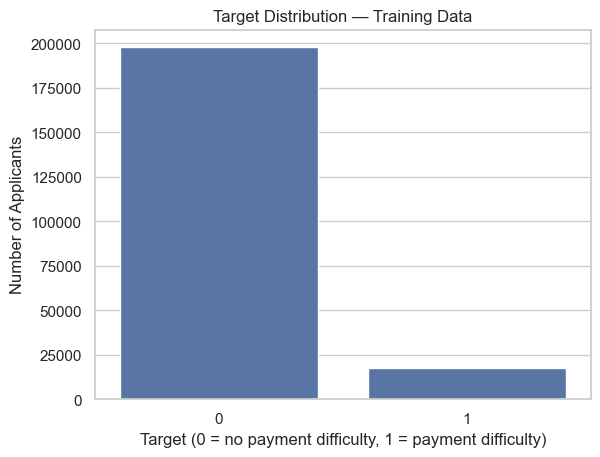

In [11]:
target_counts = df["TARGET"].value_counts().sort_index()

target_summary = pd.DataFrame({
    "Count": target_counts,
    "Percentage": (target_counts / len(df) * 100).round(2)
})

display(target_summary)

sns.countplot(data=df, x="TARGET")
plt.title("Target Distribution — Training Data")
plt.xlabel("Target (0 = no payment difficulty, 1 = payment difficulty)")
plt.ylabel("Number of Applicants")
plt.show()

In [15]:
categorical_cols = df.select_dtypes(include="object").columns

categorical_summary = pd.DataFrame({
    "Unique_Values": df[categorical_cols].nunique(),
    "Missing_Count": df[categorical_cols].isna().sum(),
    "Missing_Percentage": (
        df[categorical_cols].isna().mean() * 100
    ).round(2)
}).sort_values("Unique_Values", ascending=False)

print("Number of categorical columns:", len(categorical_cols))
display(categorical_summary)

Number of categorical columns: 16


,Unique_Values,Missing_Count,Missing_Percentage
ORGANIZATION_TYPE,58,0,0.00
OCCUPATION_TYPE,18,67365,31.30
NAME_INCOME_TYPE,8,0,0.00
NAME_TYPE_SUITE,7,893,0.41
WALLSMATERIAL_MODE,7,109369,50.81
WEEKDAY_APPR_PROCESS_START,7,0,0.00
NAME_FAMILY_STATUS,6,0,0.00
NAME_HOUSING_TYPE,6,0,0.00
NAME_EDUCATION_TYPE,5,0,0.00
FONDKAPREMONT_MODE,4,147244,68.40


In [16]:
df['OCCUPATION_TYPE'].unique()

array(['Managers', 'Sales staff', nan, 'Core staff', 'Security staff',
       'Drivers', 'Medicine staff', 'Laborers', 'Accountants',
       'High skill tech staff', 'Private service staff', 'Secretaries',
       'Waiters/barmen staff', 'Realty agents', 'Cooking staff',
       'Cleaning staff', 'HR staff', 'Low-skill Laborers', 'IT staff'],
      dtype=object)

In [17]:
df['FONDKAPREMONT_MODE'].unique()

array([nan, 'org spec account', 'reg oper account', 'not specified',
       'reg oper spec account'], dtype=object)

In [18]:
df['HOUSETYPE_MODE'].unique()

array([nan, 'block of flats', 'specific housing', 'terraced house'],
      dtype=object)

In [20]:
for column in categorical_cols:
    print(f"\n--- {column} ---")
    display(df[column].value_counts(dropna=False))


--- NAME_CONTRACT_TYPE ---


NAME_CONTRACT_TYPE
Cash loans         194707
Revolving loans     20550
Name: count, dtype: int64


--- CODE_GENDER ---


CODE_GENDER
F      141673
M       73582
XNA         2
Name: count, dtype: int64


--- FLAG_OWN_CAR ---


...

HOUSETYPE_MODE
NaN                 107937
block of flats      105406
specific housing      1055
terraced house         859
Name: count, dtype: int64


--- WALLSMATERIAL_MODE ---


WALLSMATERIAL_MODE
NaN             109369
Panel            46237
Stone, brick     45392
Block             6548
Wooden            3763
Mixed             1563
Monolithic        1277
Others            1108
Name: count, dtype: int64


--- EMERGENCYSTATE_MODE ---


EMERGENCYSTATE_MODE
No     111598
NaN    102042
Yes      1617
Name: count, dtype: int64

In [21]:
numeric_cols = df.select_dtypes(include="number").columns.drop(
    ["SK_ID_CURR", "TARGET"]
)

numeric_summary = df[numeric_cols].describe().T

display(
    numeric_summary[
        ["count", "mean", "std", "min", "25%", "50%", "75%", "max"]
    ].round(2)
)

,count,mean,std,min,25%,50%,75%,max
CNT_CHILDREN,215257.0,0.42,0.72,0.0,0.0,0.0,1.00,19.0
AMT_INCOME_TOTAL,215257.0,169073.87,274425.75,25650.0,112500.0,148500.0,202500.00,117000000.0
AMT_CREDIT,215257.0,599618.71,403093.92,45000.0,270000.0,514777.5,808650.00,4050000.0
AMT_ANNUITY,215248.0,27131.36,14570.33,1615.5,16524.0,24903.0,34628.62,258025.5
AMT_GOODS_PRICE,215065.0,538985.45,369997.62,40500.0,238500.0,450000.0,679500.00,4050000.0
...,...,...,...,...,...,...,...,...
AMT_REQ_CREDIT_BUREAU_DAY,186077.0,0.01,0.11,0.0,0.0,0.0,0.00,9.0
AMT_REQ_CREDIT_BUREAU_WEEK,186077.0,0.03,0.21,0.0,0.0,0.0,0.00,8.0
AMT_REQ_CREDIT_BUREAU_MON,186077.0,0.27,0.92,0.0,0.0,0.0,0.00,27.0
AMT_REQ_CREDIT_BUREAU_QRT,186077.0,0.26,0.61,0.0,0.0,0.0,0.00,19.0


In [22]:
comparison = []

for column in numeric_cols:
    if column.endswith("_AVG"):
        feature = column[:-4]

        avg_col = feature + "_AVG"
        medi_col = feature + "_MEDI"
        mode_col = feature + "_MODE"

        if medi_col in df.columns and mode_col in df.columns:
            correlations = df[[avg_col, medi_col, mode_col]].corr()

            comparison.append({
                "Feature": feature,
                "AVG_vs_MEDI": correlations.loc[avg_col, medi_col],
                "AVG_vs_MODE": correlations.loc[avg_col, mode_col],
                "MEDI_vs_MODE": correlations.loc[medi_col, mode_col]
            })

triplet_summary = pd.DataFrame(comparison)

display(triplet_summary.round(3))

,Feature,AVG_vs_MEDI,AVG_vs_MODE,MEDI_vs_MODE
0,APARTMENTS,0.995,0.973,0.977
1,BASEMENTAREA,0.994,0.973,0.977
2,YEARS_BEGINEXPLUATATION,0.994,0.972,0.963
3,YEARS_BUILD,0.998,0.989,0.989
4,COMMONAREA,0.996,0.978,0.981
5,ELEVATORS,0.996,0.979,0.983
6,ENTRANCES,0.997,0.978,0.981
7,FLOORSMAX,0.997,0.986,0.988
8,FLOORSMIN,0.997,0.987,0.989
9,LANDAREA,0.991,0.973,0.981


In [23]:
missing_patterns = []

for feature in triplet_summary["Feature"]:
    columns = [
        feature + "_AVG",
        feature + "_MEDI",
        feature + "_MODE"
    ]

    missing = df[columns].isna()

    same_pattern = (
        missing.iloc[:, 0].equals(missing.iloc[:, 1])
        and missing.iloc[:, 0].equals(missing.iloc[:, 2])
    )

    missing_patterns.append({
        "Feature": feature,
        "Same_Missing_Pattern": same_pattern,
        "AVG_Missing_Percentage": round(missing.iloc[:, 0].mean() * 100, 2)
    })

display(pd.DataFrame(missing_patterns))

,Feature,Same_Missing_Pattern,AVG_Missing_Percentage
0,APARTMENTS,True,50.72
1,BASEMENTAREA,True,58.50
2,YEARS_BEGINEXPLUATATION,True,48.76
3,YEARS_BUILD,True,66.51
4,COMMONAREA,True,69.88
5,ELEVATORS,True,53.27
6,ENTRANCES,True,50.32
7,FLOORSMAX,True,49.73
8,FLOORSMIN,True,67.89
9,LANDAREA,True,59.37


In [25]:
employment_summary = (
    df.groupby(df["DAYS_EMPLOYED"].eq(365243))["TARGET"]
    .agg(["count", "mean"])
)

employment_summary.index.name = "Employment_Sentinel"
employment_summary.columns = ["Applicants", "Default_Rate"]

employment_summary["Default_Rate"] = (
    employment_summary["Default_Rate"] * 100
).round(2)

display(employment_summary)

,Applicants,Default_Rate
Employment_Sentinel,,
False,176639,8.66
True,38618,5.39


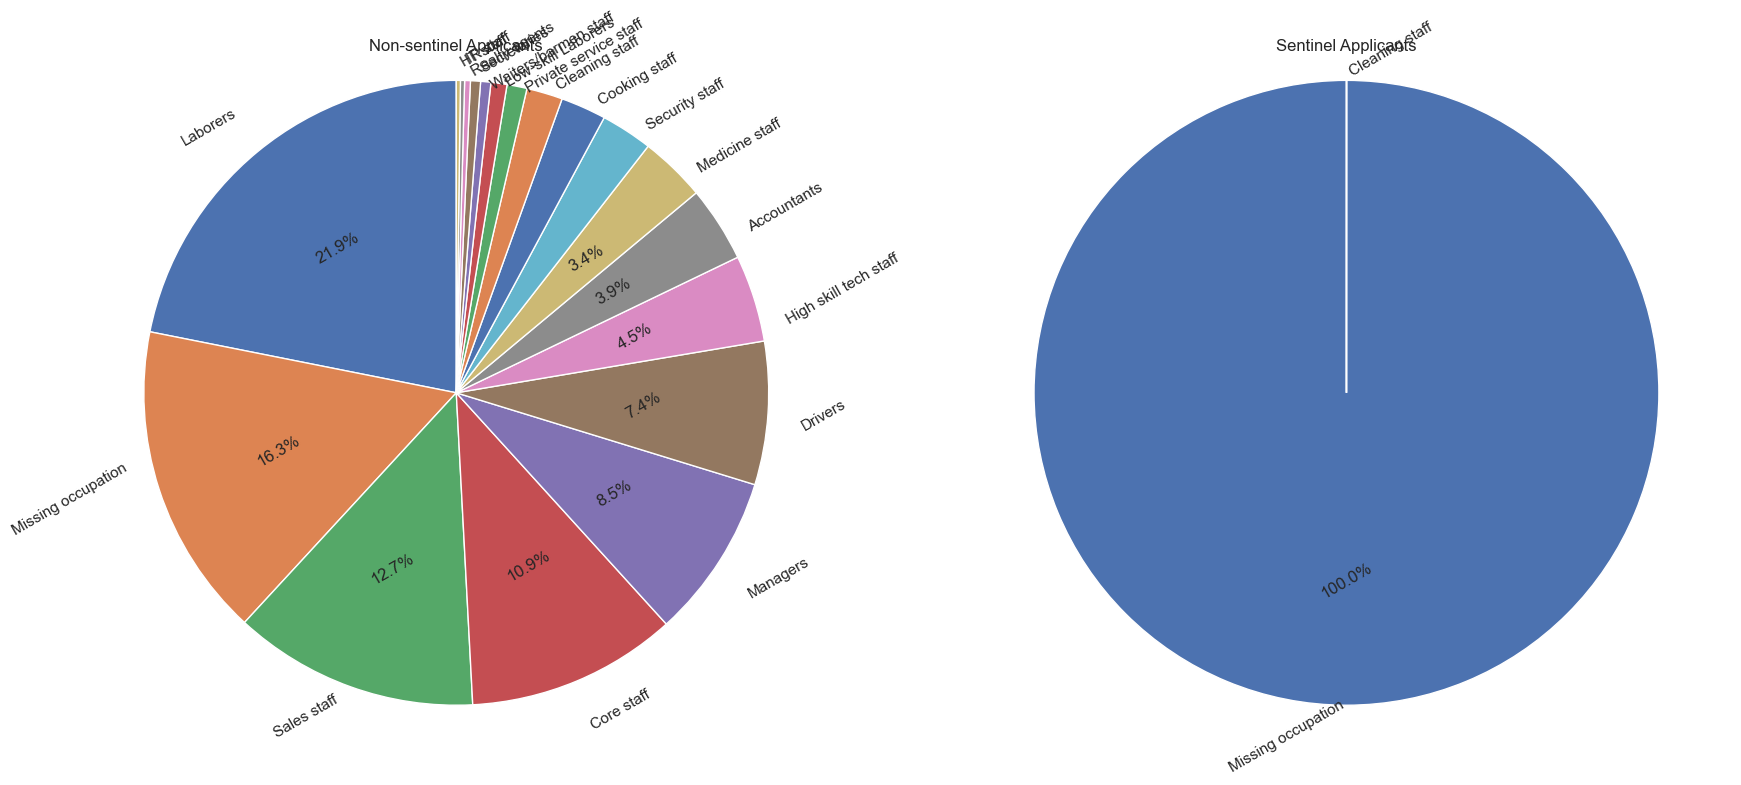

In [29]:
sentinel = df["DAYS_EMPLOYED"].eq(365243)

fig, axes = plt.subplots(1, 2, figsize=(18, 8))

for ax, group, title in [
    (axes[0], ~sentinel, "Non-sentinel Applicants"),
    (axes[1], sentinel, "Sentinel Applicants")
]:
    counts = (
        df.loc[group, "OCCUPATION_TYPE"]
        .fillna("Missing occupation")
        .value_counts()
    )

    ax.pie(
    counts,
    labels=counts.index,
    autopct=lambda pct: f"{pct:.1f}%" if pct >= 3 else "",
    startangle=90,
    textprops={"rotation": 30}
)

    ax.set_title(title)
    ax.axis("equal")

plt.tight_layout()
plt.show()

In [30]:
sentinel = df["DAYS_EMPLOYED"].eq(365243)

income_counts = (
    df.loc[sentinel, "NAME_INCOME_TYPE"]
    .fillna("Missing")
    .value_counts()
)

display(pd.DataFrame({
    "Applicants": income_counts,
    "Percentage": (income_counts / income_counts.sum() * 100).round(2)
}))

,Applicants,Percentage
NAME_INCOME_TYPE,,
Pensioner,38600,99.95
Unemployed,18,0.05


In [31]:
financial_cols = [
    "AMT_INCOME_TOTAL",
    "AMT_CREDIT",
    "AMT_ANNUITY",
    "AMT_GOODS_PRICE"
]

financial_summary = df[financial_cols].describe(
    percentiles=[0.25, 0.50, 0.75, 0.95, 0.99]
).T

display(financial_summary.round(2))

,count,mean,std,min,25%,50%,75%,95%,99%,max
AMT_INCOME_TOTAL,215257.0,169073.87,274425.75,25650.0,112500.0,148500.0,202500.00,337500.0,472500.0,117000000.0
AMT_CREDIT,215257.0,599618.71,403093.92,45000.0,270000.0,514777.5,808650.00,1350000.0,1864152.0,4050000.0
AMT_ANNUITY,215248.0,27131.36,14570.33,1615.5,16524.0,24903.0,34628.62,53329.5,70006.5,258025.5
AMT_GOODS_PRICE,215065.0,538985.45,369997.62,40500.0,238500.0,450000.0,679500.00,1305000.0,1800000.0,4050000.0


In [32]:
columns_to_view = [
    "AMT_INCOME_TOTAL",
    "AMT_CREDIT",
    "AMT_ANNUITY",
    "NAME_INCOME_TYPE",
    "OCCUPATION_TYPE",
    "TARGET"
]

display(
    df.nlargest(10, "AMT_INCOME_TOTAL")[columns_to_view]
)

,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,NAME_INCOME_TYPE,OCCUPATION_TYPE,TARGET
16690,117000000.0,562491.0,26194.5,Working,Laborers,1
67906,18000090.0,675000.0,69295.5,Commercial associate,NaN,0
204901,9000000.0,1431531.0,132601.5,Working,Managers,0
5754,4500000.0,835380.0,42651.0,Working,Laborers,0
12226,4500000.0,450000.0,47749.5,Working,Managers,0
59817,4500000.0,2250000.0,225000.0,Working,Managers,0
47882,3950059.5,675000.0,66217.5,Commercial associate,Managers,0
120165,3825000.0,1241023.5,117369.0,Commercial associate,Managers,0
176214,3600000.0,1113840.0,44302.5,Working,Core staff,0
210897,3600000.0,953460.0,68791.5,Commercial associate,NaN,0


In [33]:
df.drop(
    index=df.index[df["AMT_INCOME_TOTAL"].eq(117000000)],
    inplace=True
)

print("Remaining training rows:", len(df))

Remaining training rows: 215256


In [34]:
df.to_csv(SPLIT_DIR / "train.csv", index=False)

print("Updated train.csv saved.")
print("Training rows:", len(df))

Updated train.csv saved.
Training rows: 215256


,Applicants,Payment_Difficulty_Cases,Payment_Difficulty_Rate
Age_Group,,,
20-29,31781,3640,11.45
30-39,57589,5515,9.58
40-49,53635,4122,7.69
50-59,47622,2886,6.06
60-69,24629,1213,4.93


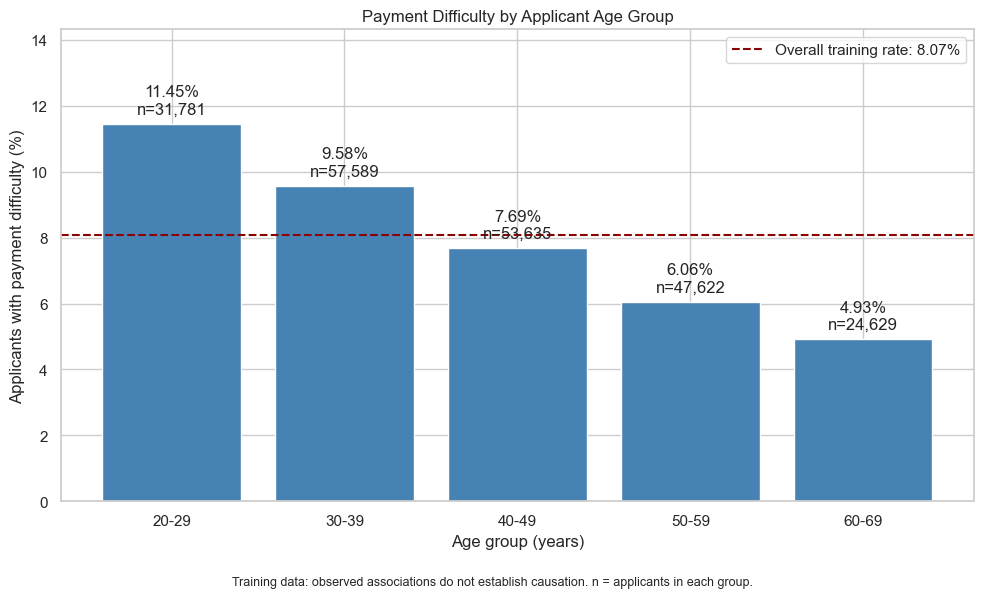

In [ ]:
age_years = -df["DAYS_BIRTH"] / 365.25
age_groups = pd.cut(
    age_years,
    bins=[0, 20, 30, 40, 50, 60, 70, float("inf")],
    labels=["Under 20", "20-29", "30-39", "40-49", "50-59", "60-69", "70+"],
    right=False
)

age_summary = (
    df.groupby(age_groups, observed=True)["TARGET"]
    .agg(Applicants="size", Payment_Difficulty_Cases="sum", Payment_Difficulty_Rate="mean")
)
age_summary.index.name = "Age_Group"
age_summary["Payment_Difficulty_Rate"] *= 100

display(age_summary.round(2))

baseline_rate = df["TARGET"].mean() * 100
fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.bar(
    age_summary.index.astype(str),
    age_summary["Payment_Difficulty_Rate"],
    color="steelblue"
)
ax.axhline(
    baseline_rate, color="darkred", linestyle="--",
    label=f"Overall training rate: {baseline_rate:.2f}%"
)
for bar, (_, row) in zip(bars, age_summary.iterrows()):
    ax.annotate(
        f"{row['Payment_Difficulty_Rate']:.2f}%\nn={int(row['Applicants']):,}",
        (bar.get_x() + bar.get_width() / 2, bar.get_height()),
        xytext=(0, 5), textcoords="offset points", ha="center", va="bottom"
    )
ax.set_title("Payment Difficulty by Applicant Age Group")
ax.set_xlabel("Age group (years)")
ax.set_ylabel("Applicants with payment difficulty (%)")
ax.set_ylim(0, max(age_summary["Payment_Difficulty_Rate"].max(), baseline_rate) * 1.25)
ax.legend()
fig.text(
    0.5, 0.01,
    "Training data: observed associations do not establish causation. n = applicants in each group.",
    ha="center", fontsize=9
)
plt.tight_layout(rect=[0, 0.04, 1, 1])
plt.show()


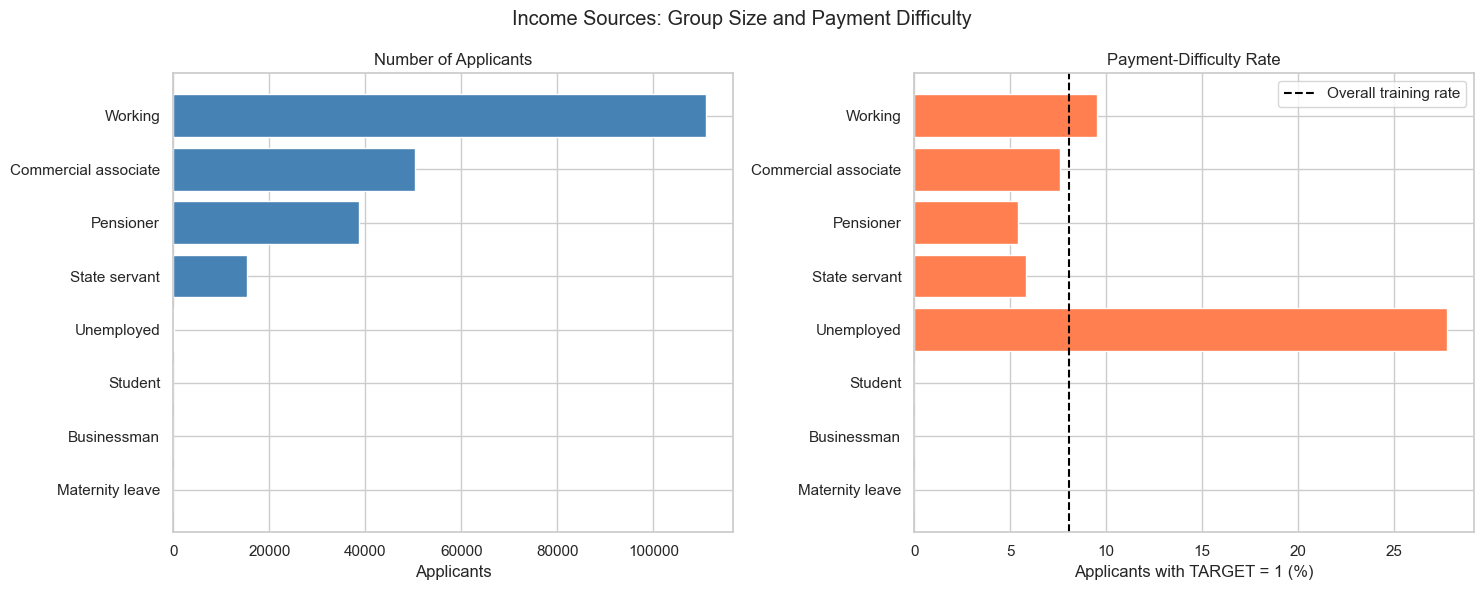

In [37]:
income_summary = (
    df.groupby("NAME_INCOME_TYPE")
    .agg(
        Applicants=("TARGET", "size"),
        Difficulty_Rate=("TARGET", "mean")
    )
    .sort_values("Applicants")
)

income_summary["Difficulty_Rate"] *= 100

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

axes[0].barh(
    income_summary.index,
    income_summary["Applicants"],
    color="steelblue"
)
axes[0].set_title("Number of Applicants")
axes[0].set_xlabel("Applicants")

axes[1].barh(
    income_summary.index,
    income_summary["Difficulty_Rate"],
    color="coral"
)
axes[1].axvline(
    df["TARGET"].mean() * 100,
    color="black",
    linestyle="--",
    label="Overall training rate"
)
axes[1].set_title("Payment-Difficulty Rate")
axes[1].set_xlabel("Applicants with TARGET = 1 (%)")
axes[1].legend()

plt.suptitle("Income Sources: Group Size and Payment Difficulty")
plt.tight_layout()
plt.show()

,Applicants,Difficulty_Rate
"(0.0365, 1.82]",43052,7.23
"(1.82, 2.765]",43068,8.56
"(2.765, 3.909]",43034,8.95
"(3.909, 5.775]",43053,8.27
"(5.775, 49.227]",43049,7.35


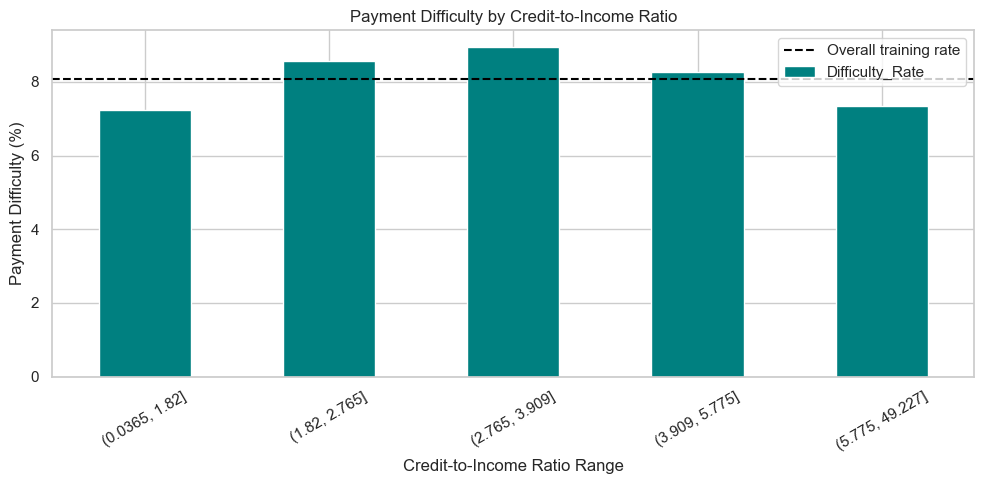

In [38]:
credit_income_ratio = (
    df["AMT_CREDIT"] / df["AMT_INCOME_TOTAL"].replace(0, float("nan"))
)

ratio_group = pd.qcut(
    credit_income_ratio,
    q=5,
    duplicates="drop"
)

ratio_summary = (
    df.groupby(ratio_group, observed=True)["TARGET"]
    .agg(["size", "mean"])
)

ratio_summary.columns = ["Applicants", "Difficulty_Rate"]
ratio_summary["Difficulty_Rate"] *= 100

display(ratio_summary.round(2))

ratio_summary["Difficulty_Rate"].plot(
    kind="bar",
    figsize=(10, 5),
    color="teal",
    rot=30
)

plt.axhline(
    df["TARGET"].mean() * 100,
    color="black",
    linestyle="--",
    label="Overall training rate"
)

plt.title("Payment Difficulty by Credit-to-Income Ratio")
plt.xlabel("Credit-to-Income Ratio Range")
plt.ylabel("Payment Difficulty (%)")
plt.legend()
plt.tight_layout()
plt.show()

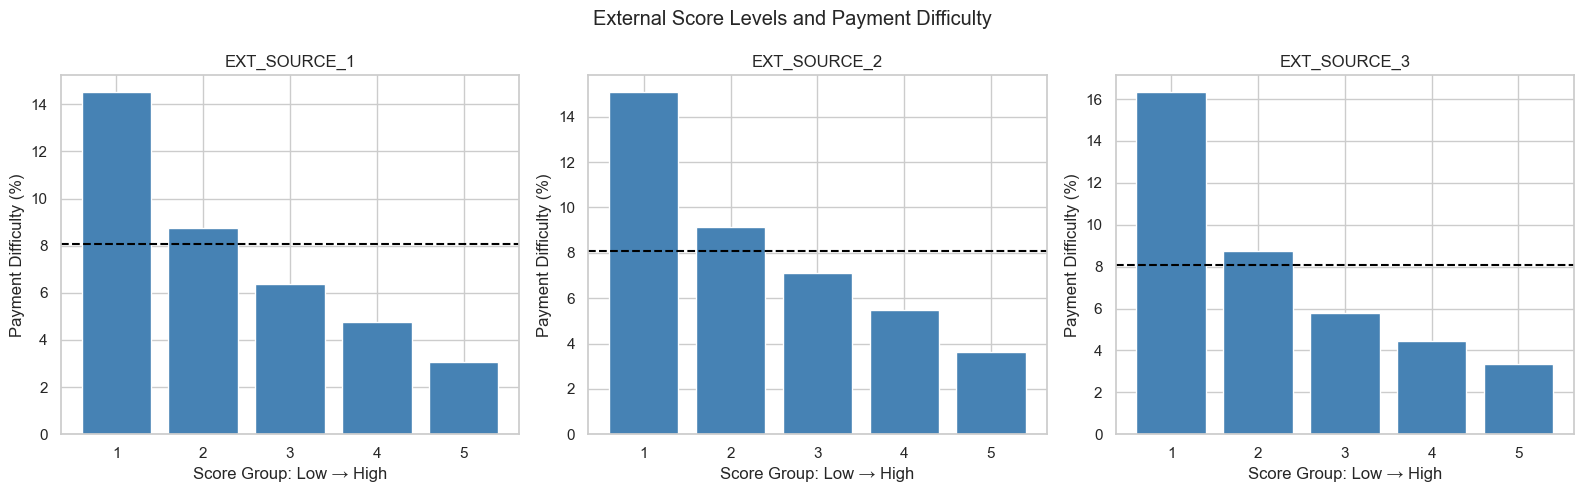

In [39]:
score_columns = ["EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3"]

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, column in zip(axes, score_columns):
    score_group = pd.qcut(df[column], q=5, duplicates="drop")

    rates = df.groupby(
        score_group, observed=True
    )["TARGET"].mean() * 100

    ax.bar(range(len(rates)), rates.values, color="steelblue")

    ax.axhline(
        df["TARGET"].mean() * 100,
        color="black",
        linestyle="--"
    )

    ax.set_title(column)
    ax.set_xlabel("Score Group: Low → High")
    ax.set_xticks(range(len(rates)))
    ax.set_xticklabels(range(1, len(rates) + 1))
    ax.set_ylabel("Payment Difficulty (%)")

plt.suptitle("External Score Levels and Payment Difficulty")
plt.tight_layout()
plt.show()

,Feature,Score_Status,Applicants,Difficulty_Rate
0,EXT_SOURCE_1,Available,93964,7.48
1,EXT_SOURCE_1,Missing,121292,8.53
2,EXT_SOURCE_2,Available,214799,8.07
3,EXT_SOURCE_2,Missing,457,6.78
4,EXT_SOURCE_3,Available,172397,7.75
5,EXT_SOURCE_3,Missing,42859,9.35


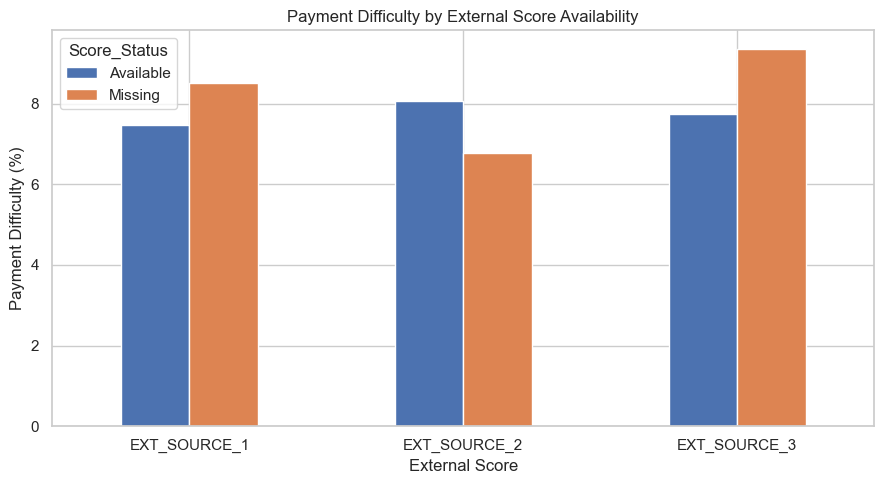

In [40]:
score_missing_summary = []

for column in score_columns:
    for missing in [False, True]:
        group = df.loc[df[column].isna() == missing]

        score_missing_summary.append({
            "Feature": column,
            "Score_Status": "Missing" if missing else "Available",
            "Applicants": len(group),
            "Difficulty_Rate": group["TARGET"].mean() * 100
        })

score_missing_summary = pd.DataFrame(score_missing_summary)

display(score_missing_summary.round(2))

score_missing_summary.pivot(
    index="Feature",
    columns="Score_Status",
    values="Difficulty_Rate"
).plot.bar(figsize=(9, 5), rot=0)

plt.title("Payment Difficulty by External Score Availability")
plt.ylabel("Payment Difficulty (%)")
plt.xlabel("External Score")
plt.tight_layout()
plt.show()

# onto pre processing now